In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('Myocardial_infarction_complications.csv')
df

,ID,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,IBS_NASL,GB,SIM_GIPERT,...,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,1,77.0,1,2.0,1.0,1.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1,2,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,3,52.0,1,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,4,68.0,0,0.0,0.0,0.0,2.0,NaN,2.0,0.0,...,0,0,0,0,0,0,1,0,0,0
4,5,60.0,1,0.0,0.0,0.0,2.0,NaN,3.0,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1695,1696,77.0,0,0.0,4.0,2.0,1.0,NaN,2.0,0.0,...,0,0,1,0,1,0,0,0,0,3
1696,1697,70.0,0,0.0,6.0,2.0,1.0,NaN,2.0,0.0,...,0,0,0,0,0,0,0,0,0,1
1697,1698,55.0,1,3.0,6.0,2.0,2.0,NaN,0.0,0.0,...,0,0,0,0,0,0,0,1,0,6
1698,1699,79.0,0,2.0,2.0,2.0,1.0,NaN,2.0,0.0,...,0,0,0,1,0,0,0,0,0,1


In [3]:
df = df.drop(["ID"], axis=1)


In [4]:
missing_values = df.isnull().sum()
missing_values

AGE            8
SEX            0
INF_ANAM       4
STENOK_AN    106
FK_STENOK     73
            ... 
DRESSLER       0
ZSN            0
REC_IM         0
P_IM_STEN      0
LET_IS         0
Length: 123, dtype: int64

In [5]:
# 删除缺失值较多的列（例如缺失值超过80%的列）
threshold = len(df) * 0.8
df = df.dropna(thresh=threshold, axis=1)
df

,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,GB,SIM_GIPERT,DLIT_AG,ZSN_A,...,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,77.0,1,2.0,1.0,1.0,2.0,3.0,0.0,7.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1,55.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,52.0,1,0.0,0.0,0.0,2.0,2.0,0.0,2.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,68.0,0,0.0,0.0,0.0,2.0,2.0,0.0,3.0,1.0,...,0,0,0,0,0,0,1,0,0,0
4,60.0,1,0.0,0.0,0.0,2.0,3.0,0.0,7.0,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1695,77.0,0,0.0,4.0,2.0,1.0,2.0,0.0,7.0,0.0,...,0,0,1,0,1,0,0,0,0,3
1696,70.0,0,0.0,6.0,2.0,1.0,2.0,0.0,7.0,0.0,...,0,0,0,0,0,0,0,0,0,1
1697,55.0,1,3.0,6.0,2.0,2.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,1,0,6
1698,79.0,0,2.0,2.0,2.0,1.0,2.0,0.0,7.0,NaN,...,0,0,0,1,0,0,0,0,0,1


In [6]:
# 填充剩余的缺失值（用均值填充数值列，用众数填充类别列）
for col in df.columns:
    if df[col].dtype == "object":
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].mean(), inplace=True)
        

/var/folders/10/6bnmz8v50_l76xr7kydjjfb00000gn/T/ipykernel_39727/3671355495.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mean(), inplace=True)


In [7]:
df

,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,GB,SIM_GIPERT,DLIT_AG,ZSN_A,...,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,77.0,1,2.0,1.000000,1.000000,2.000000,3.0,0.0,7.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
1,55.0,1,1.0,0.000000,0.000000,0.000000,0.0,0.0,0.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
2,52.0,1,0.0,0.000000,0.000000,2.000000,2.0,0.0,2.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
3,68.0,0,0.0,0.000000,0.000000,2.000000,2.0,0.0,3.00000,1.000000,...,0,0,0,0,0,0,1,0,0,0
4,60.0,1,0.0,0.000000,0.000000,2.000000,3.0,0.0,7.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1695,77.0,0,0.0,4.000000,2.000000,1.000000,2.0,0.0,7.00000,0.000000,...,0,0,1,0,1,0,0,0,0,3
1696,70.0,0,0.0,6.000000,2.000000,1.000000,2.0,0.0,7.00000,0.000000,...,0,0,0,0,0,0,0,0,0,1
1697,55.0,1,3.0,6.000000,2.000000,2.000000,0.0,0.0,0.00000,0.000000,...,0,0,0,0,0,0,0,1,0,6
1698,79.0,0,2.0,2.000000,2.000000,1.000000,2.0,0.0,7.00000,0.194411,...,0,0,0,1,0,0,0,0,0,1


In [8]:
target_column = 'LET_IS'
# 查看目标变量的值计数
target_distribution = df[target_column].value_counts()
print("目标变量的类别分布：")
print(target_distribution)

# 查看目标变量的分布比例
target_percentage = df[target_column].value_counts(normalize=True) * 100
print("\n目标变量的类别分布百分比：")
print(target_percentage)

目标变量的类别分布：
LET_IS
0    1429
1     110
3      54
7      27
6      27
4      23
2      18
5      12
Name: count, dtype: int64

目标变量的类别分布百分比：
LET_IS
0    84.058824
1     6.470588
3     3.176471
7     1.588235
6     1.588235
4     1.352941
2     1.058824
5     0.705882
Name: proportion, dtype: float64


In [9]:
# 将所有非0的值转换为1
df[target_column] = df[target_column].apply(lambda x: 1 if x != 0 else 0)

# 查看转换后的目标变量分布
target_distribution_after = df[target_column].value_counts()
print("转换后目标变量的类别分布：")
print(target_distribution_after)

转换后目标变量的类别分布：
LET_IS
0    1429
1     271
Name: count, dtype: int64


In [10]:
df

,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,GB,SIM_GIPERT,DLIT_AG,ZSN_A,...,JELUD_TAH,FIBR_JELUD,A_V_BLOK,OTEK_LANC,RAZRIV,DRESSLER,ZSN,REC_IM,P_IM_STEN,LET_IS
0,77.0,1,2.0,1.000000,1.000000,2.000000,3.0,0.0,7.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
1,55.0,1,1.0,0.000000,0.000000,0.000000,0.0,0.0,0.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
2,52.0,1,0.0,0.000000,0.000000,2.000000,2.0,0.0,2.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
3,68.0,0,0.0,0.000000,0.000000,2.000000,2.0,0.0,3.00000,1.000000,...,0,0,0,0,0,0,1,0,0,0
4,60.0,1,0.0,0.000000,0.000000,2.000000,3.0,0.0,7.00000,0.000000,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1695,77.0,0,0.0,4.000000,2.000000,1.000000,2.0,0.0,7.00000,0.000000,...,0,0,1,0,1,0,0,0,0,1
1696,70.0,0,0.0,6.000000,2.000000,1.000000,2.0,0.0,7.00000,0.000000,...,0,0,0,0,0,0,0,0,0,1
1697,55.0,1,3.0,6.000000,2.000000,2.000000,0.0,0.0,0.00000,0.000000,...,0,0,0,0,0,0,0,1,0,1
1698,79.0,0,2.0,2.000000,2.000000,1.000000,2.0,0.0,7.00000,0.194411,...,0,0,0,1,0,0,0,0,0,1


In [11]:
df.to_csv('MIC_processing.csv', index=False)

In [12]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score
import lightgbm as lgb
X = df.drop(columns=['LET_IS'])  # 特征
y = df['LET_IS']  # 目标变量

# 2. 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
import lightgbm as lgb
from sklearn.metrics import confusion_matrix,accuracy_score,roc_curve,classification_report,f1_score,accuracy_score

model = lgb.LGBMClassifier(verbose=-1)

model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test)

In [14]:
f1_score(y_test, y_pred)

0.8222222222222222

In [15]:
classification_report(y_test, y_pred)

'              precision    recall  f1-score   support\n\n           0       0.95      1.00      0.97       288\n           1       0.97      0.71      0.82        52\n\n    accuracy                           0.95       340\n   macro avg       0.96      0.85      0.90       340\nweighted avg       0.95      0.95      0.95       340\n'

In [16]:
accuracy_score(y_test, y_pred)

0.9529411764705882

/opt/anaconda3/envs/XAI/lib/python3.10/site-packages/shap/explainers/_tree.py:448: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn('LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray')


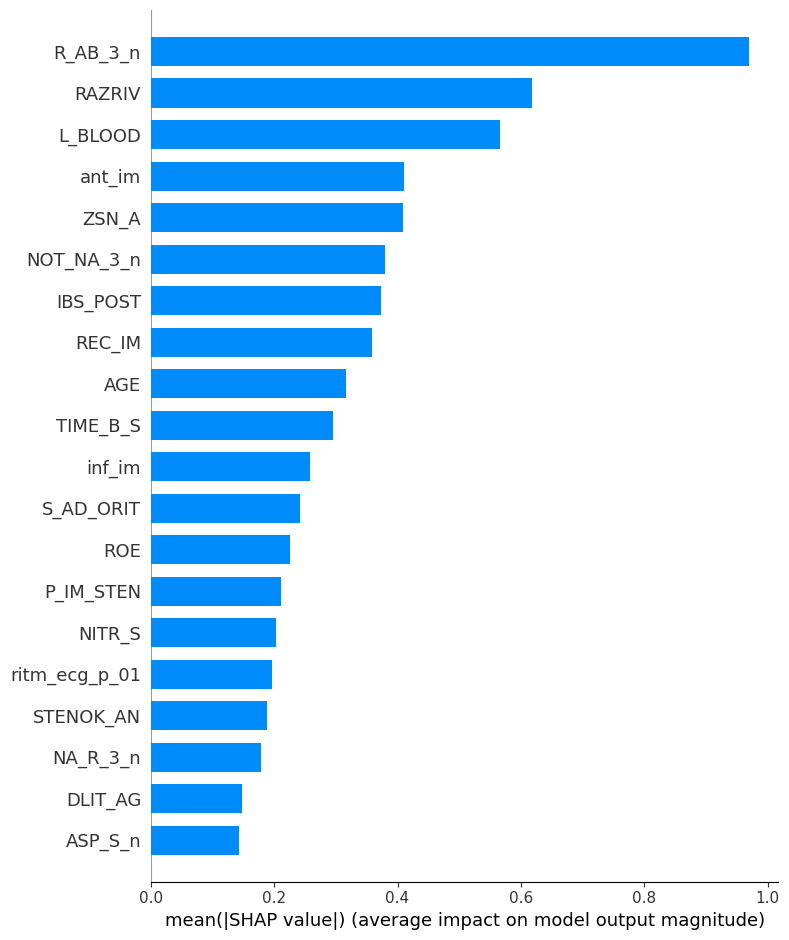

In [18]:
import shap
explainer = shap.Explainer(model)
shap_values = explainer.shap_values(X_test)
feature_names = X.columns.tolist()
shap.summary_plot(shap_values, X_test, plot_type="bar", feature_names=feature_names)

In [20]:
import numpy as np # linear algebra

shap_values = explainer.shap_values(X_test)
feature_importance = np.abs(shap_values).mean(axis=0)
sorted_feature_indices = np.argsort(feature_importance)[::-1]
sorted_features = X.columns[sorted_feature_indices][:30]
sorted_features

/opt/anaconda3/envs/XAI/lib/python3.10/site-packages/shap/explainers/_tree.py:448: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn('LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray')


Index(['R_AB_3_n', 'RAZRIV', 'L_BLOOD', 'ant_im', 'ZSN_A', 'NOT_NA_3_n',
       'IBS_POST', 'REC_IM', 'AGE', 'TIME_B_S', 'inf_im', 'S_AD_ORIT', 'ROE',
       'P_IM_STEN', 'NITR_S', 'ritm_ecg_p_01', 'STENOK_AN', 'NA_R_3_n',
       'DLIT_AG', 'ASP_S_n', 'INF_ANAM', 'IM_PG_P', 'D_AD_ORIT',
       'n_p_ecg_p_12', 'ZSN', 'ALT_BLOOD', 'AST_BLOOD', 'endocr_01', 'lat_im',
       'post_im'],
      dtype='object')

/var/folders/10/6bnmz8v50_l76xr7kydjjfb00000gn/T/ipykernel_39727/2849053146.py:54: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()  # 调整布局以避免标签重叠


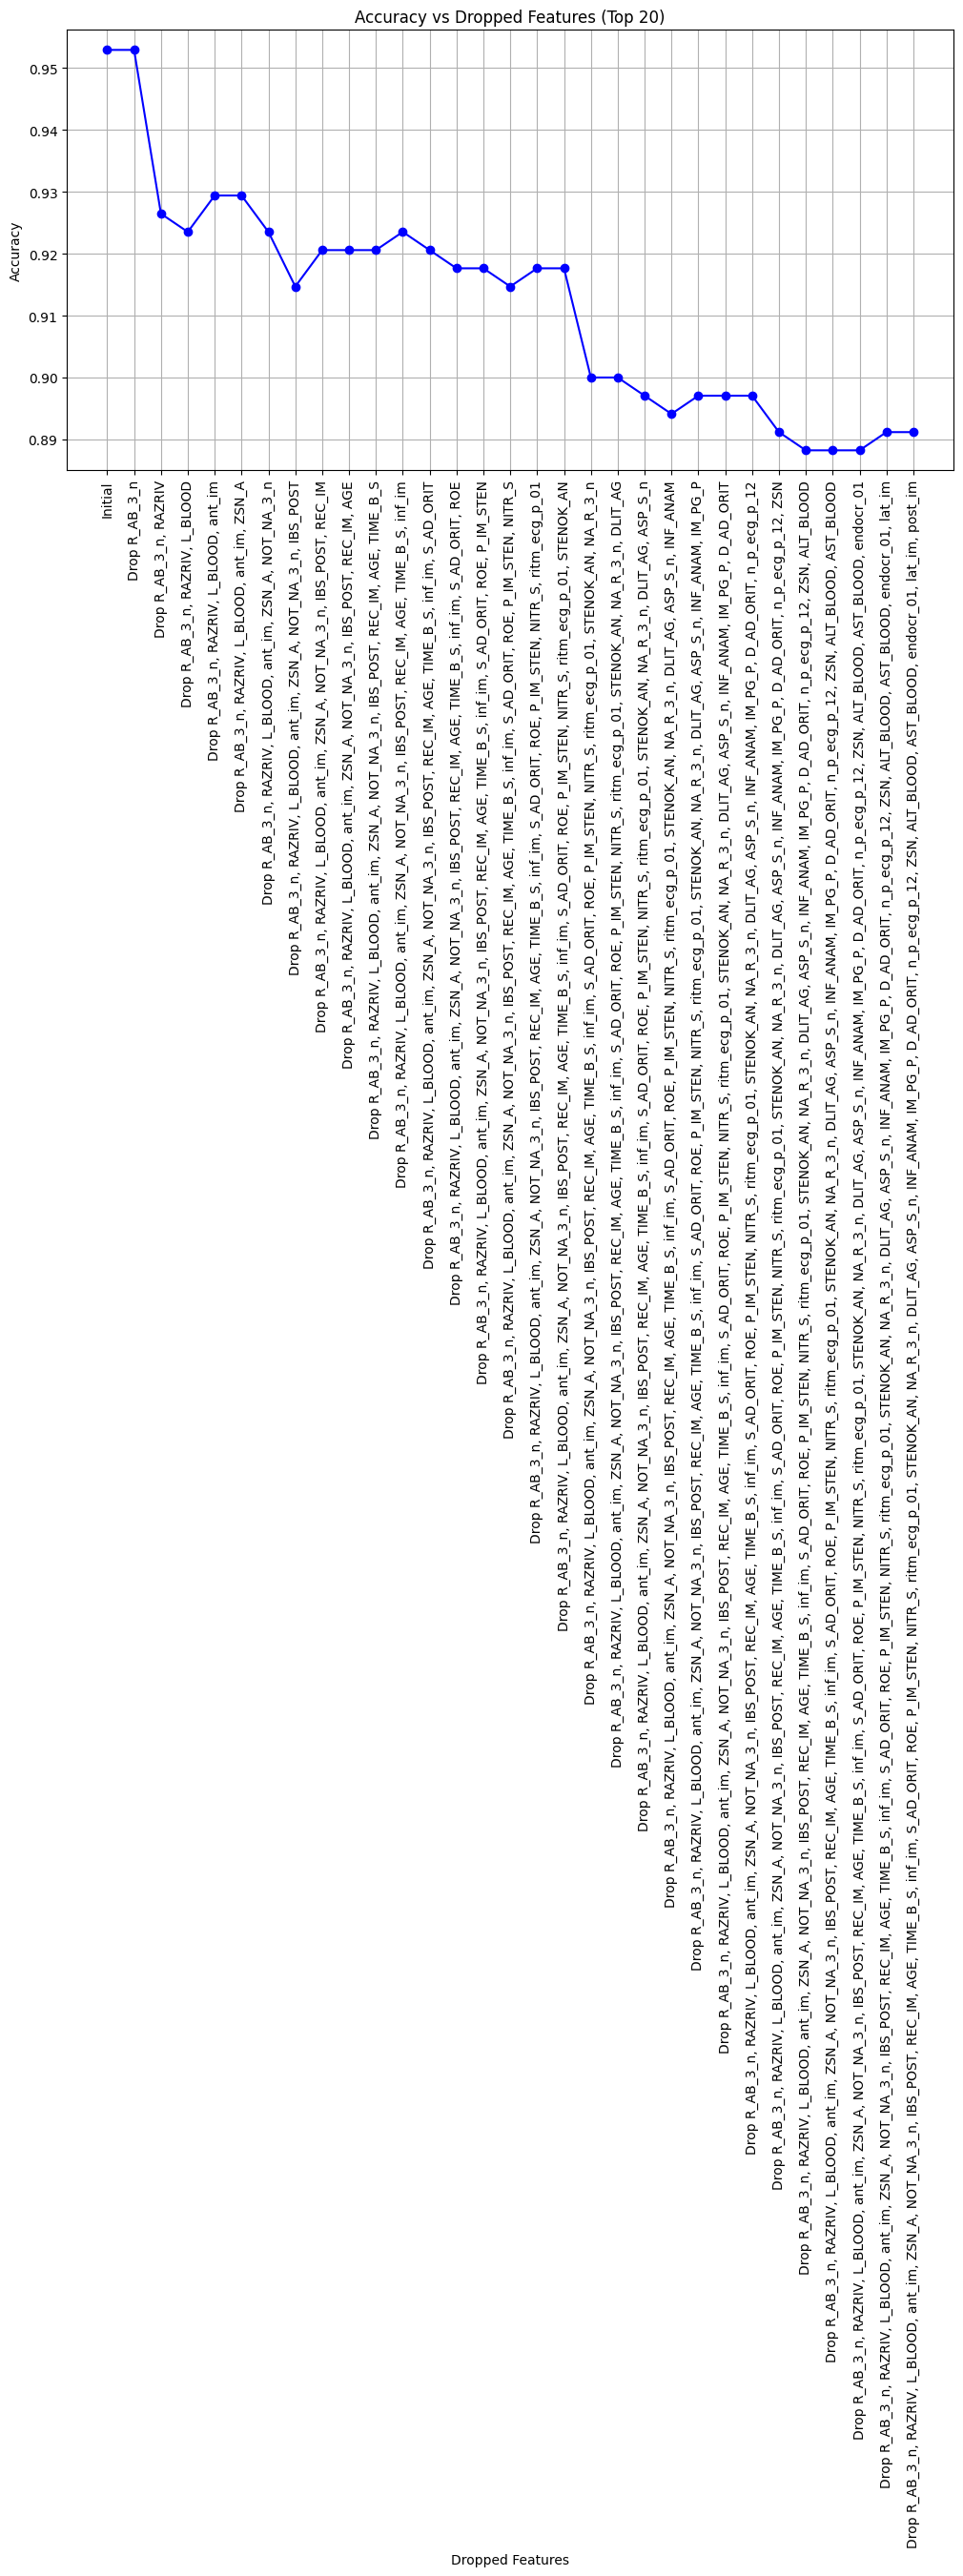

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
# 初始化结果存储
initial_accuracy = accuracy_score(y_test, y_pred)

results = {}

# 初始模型的准确率
# initial_accuracy = accuracy_score(y_test, lgb_pred_test)
results['Initial'] = {'Features': [], 'Accuracy': initial_accuracy}

# 只计算前20个最重要的特征
num_features_to_drop = 30

# 逐步删除最重要的特征并观察准确率变化
for i in range(1, num_features_to_drop + 1):
    features_to_drop = sorted_features[:i]
    reduced_X = X.drop(columns=features_to_drop)
    
    # 分割数据集
    X_train, X_test, y_train, y_test = train_test_split(reduced_X, y, test_size=0.2, random_state=42)
    
    model = lgb.LGBMClassifier(verbose=-1)

    model.fit(X_train, y_train)

# Make predictions on the test set
    y_pred = model.predict(X_test)
    new_accuracy = accuracy_score(y_test, y_pred)
    
    # 存储结果
    results[f'Step {i}'] = {'Features': features_to_drop, 'Accuracy': new_accuracy}

# # 打印结果
# for step, result in results.items():
#     print(f"{step}: Dropped Features: {result['Features']}, Accuracy: {result['Accuracy']}")

# 提取前20个步骤的结果
steps = list(results.keys())
accuracies = [results[step]['Accuracy'] for step in steps]
dropped_features = [results[step]['Features'] for step in steps]

# 创建横坐标标签（删除的特征）
x_labels = ['Initial'] + [f"Drop {', '.join(features)}" for features in dropped_features[1:]]

# 绘制准确率变化图
plt.figure(figsize=(12, 6))
plt.plot(x_labels, accuracies, marker='o', linestyle='-', color='b')
plt.xticks(rotation=90)  # 旋转横坐标标签
plt.xlabel('Dropped Features')
plt.ylabel('Accuracy')
plt.title('Accuracy vs Dropped Features (Top 20)')
plt.grid(True)
plt.tight_layout()  # 调整布局以避免标签重叠
plt.show()